TARDIS MODEL

In this notebook, we develop a regression model to predict the "Average delay of all trains at arrival".

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
df = pd.read_csv("cleaned_dataset.csv")

In [3]:
features = [
    "Service",
    "Departure station",
    "Arrival station",
    "Month",
    "Year",
    "Number of scheduled trains",
]

X = df[features]
Y = df["Average delay of all trains at arrival"]

Choosing the right features is critical for building a predictive model that works in real-world scenarios. We have selected the following based on their logical impact on train delay, as well on their availability prior to the journey.

One-Hot Encoding and Split

In [4]:
X_encoded = pd.get_dummies(
    X, columns=["Service", "Departure station", "Arrival station"], drop_first=True
)

X_train, X_test, Y_train, Y_test = train_test_split(
    X_encoded, Y, test_size=0.2, random_state=42
)

print("Nb rows for training: ", len(X_train))
print("Nb rows for testing: ", len(X_test))

Nb rows for training:  9232
Nb rows for testing:  2309


Since machine learning algorithms cannot process text, we converted strings into numerical values (0 and 1) using One-Hot Encoding.
Also, we divided the dataset into a Training Set (80%) to teach the model and a Test Set (20%) to evaluate its performance.

Baseline Model

Mean strategy: we calculate the average delay in the train set and use it as a constant prediction in the test set.
Our regression models must achieve a significantly lower Mean Absolute Error than the baseline model.

In [5]:
baseline_value = Y_train.mean()

y_baseline = [baseline_value] * len(Y_test)
mae_baseline = mean_absolute_error(Y_test, y_baseline)
rmse_baseline = np.sqrt(mean_squared_error(Y_test, y_baseline))

print(f"Baseline Mean Prediction: {baseline_value:.2f} minutes")
print(f"Baseline MAE: {mae_baseline:.2f} minutes")
print(f"Baseline RMSE: {rmse_baseline:.2f} minutes")

Baseline Mean Prediction: 5.98 minutes
Baseline MAE: 3.19 minutes
Baseline RMSE: 5.75 minutes


Linear Regression

In [6]:
lin_regr_model = LinearRegression()

lin_regr_model.fit(X_train, Y_train)
lin_regr_pred = lin_regr_model.predict(X_test)

mae_lin_regr = mean_absolute_error(Y_test, lin_regr_pred)
r2_lin_regr = r2_score(Y_test, lin_regr_pred)

print(f"Linear Regression MAE: {mae_lin_regr:.2f} minutes")
print(f"R2 score: {r2_lin_regr:.3f}")

Linear Regression MAE: 2.57 minutes
R2 score: 0.127


We implement a Linear Regression model. The model learns from the X_train and finds a mathematical equation that best connects our features to the arrival delays. Afterwards, we use it to estimate delays for the journeys in the X_test.

Random Forest Regressor

In [7]:
rf_regr_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_regr_model.fit(X_train, Y_train)
rf_regr_pred = rf_regr_model.predict(X_test)

mae_rf_regr = mean_absolute_error(Y_test, rf_regr_pred)
r2_rf_regr = r2_score(Y_test, rf_regr_pred)

print(f"Random Forest MAE: {mae_rf_regr:.2f} minutes")
print(f"R2 score: {r2_rf_regr:.3f}")

Random Forest MAE: 2.28 minutes
R2 score: 0.024


We implement a Random Forest Regressor. Instead of searching for a single linear equation, this model uses a collection of 100 trees to analyze the data.

To evaluate the accuracy of our Random Forest Regressor, we visualize the relationship between the actual delays and the predicted delays using a scatter plot.

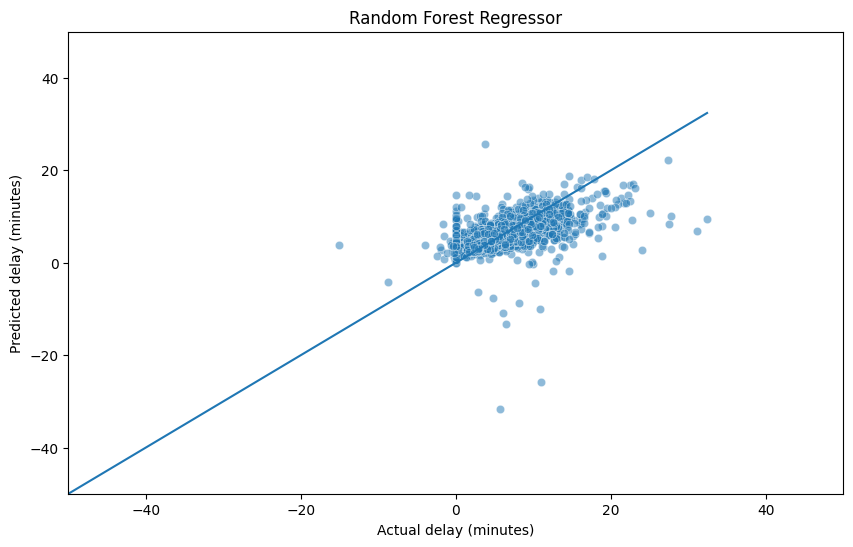

In [8]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x=Y_test, y=rf_regr_pred, alpha=0.5)
plt.plot([Y_test.min(), Y_test.max()], [Y_test.min(), Y_test.max()])

plt.xlim(-50, 50)
plt.ylim(-50, 50)

plt.xlabel("Actual delay (minutes)")
plt.ylabel("Predicted delay (minutes)")
plt.title("Random Forest Regressor")

plt.show()

Hyperparameter Tuning

In [9]:
param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)

grid_search.fit(X_train, Y_train)

best_rf_model = grid_search.best_estimator_
print(f"Best settings: {grid_search.best_params_}")

Best settings: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}


To optimize the Random Forest Regressor model, we use GridSearchCV with Cross-Validation with 5 partitions. We explore 27 combinations of hyperparameters to find the one that minimizes the MAE.

Model Performance Comparison

In [10]:
tuned_pred = best_rf_model.predict(X_test)
tuned_mae = mean_absolute_error(Y_test, tuned_pred)
tuned_r2 = r2_score(Y_test, tuned_pred)

comparison_data = {
    "Model": ["Random Forest (Standard)", "Random Forest (Tuned)"],
    "MAE (minutes)": [2.28, tuned_mae],
    "R2 Score": [0.041, tuned_r2],
}

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison)

                      Model  MAE (minutes)  R2 Score
0  Random Forest (Standard)       2.280000  0.041000
1     Random Forest (Tuned)       2.262813  0.148513


We compare the performance of the optimized Random Forest with the initial version to see the improvements gained through hyperparameter tuning.

Feature Importance

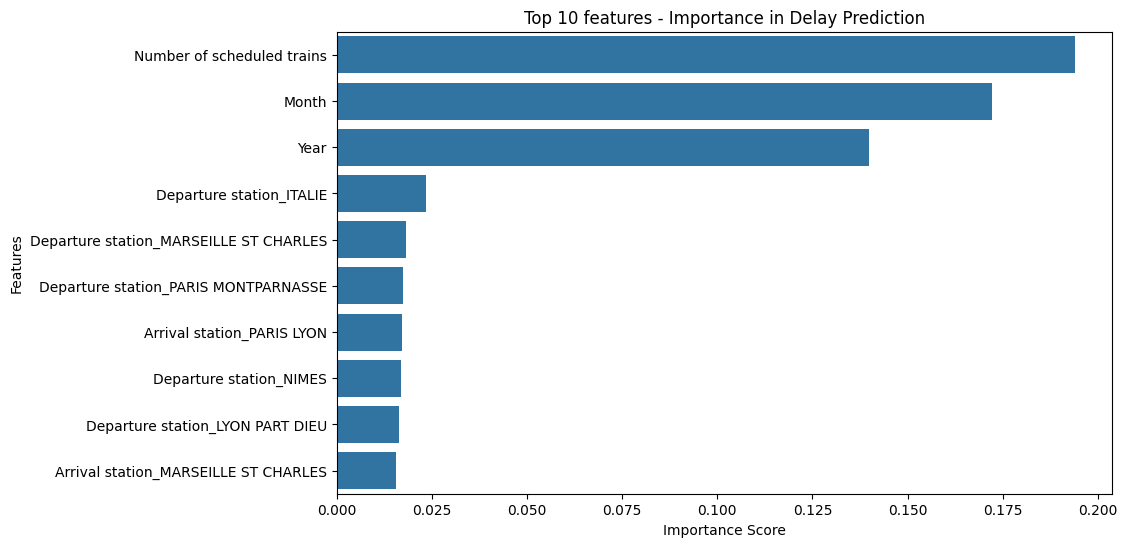

In [11]:
importances = best_rf_model.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame(
    {"Feature": feature_names, "Importance": importances}
)

feature_importance_df = feature_importance_df.sort_values(
    by="Importance", ascending=False
).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x="Importance", y="Feature", data=feature_importance_df)
plt.title("Top 10 features - Importance in Delay Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

Visualisation of the top 10 features that have the most significant impact on delay predictions.

Model Export

In [12]:
joblib.dump(best_rf_model, "model.joblib")
print("The model was saved")

The model was saved


## Feature Importance Analysis

In [ ]:
import pandas as pd

feature_importance = pd.Series(
    best_rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

feature_importance.head(10)

feature_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Feature Importances in Random Forest"
)

This section examines the most important features used by the Random Forest model. Feature importance helps explain which variables contribute the most to predicting Average delay of all trains at arrival.

Among the tested models, the Random Forest Regressor achieved the lowest MAE, which means it produced the most accurate predictions on average. For this reason, it was selected as the final model for interpretation. The feature importance analysis helps identify which variables the model relies on most strongly when predicting arrival delays.

The feature importance results show which variables have the strongest influence on the model. If station-related features appear near the top, this suggests that location and route structure are major factors in arrival delay. If month- or year-related features are important, this suggests that time-based patterns such as seasonality also affect train performance. This makes the Random Forest model more interpretable instead of treating it as a complete black box.